# Etapa 1: curadoria da base

Reconstrução da base MultiTarget Bioactivity a partir da API do ChEMBL. A análise exploratória da base final fica em `02_analise_exploratoria.ipynb`.

O código fica em `src/`, um módulo por etapa (`download`, `inspection`, `curation`, `eda`, `plots`). Os downloads ficam em cache em `data/raw/`; `REFRESH = True` força novo download.

## 0. Configuração

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

%load_ext autoreload
%autoreload 2

import pandas as pd
from IPython.display import display

from src import chembl_api, curation, download, eda, inspection, plots
from src.config import ACTIVE_THRESHOLD, ACTIVITIES_CSV, FINAL_CSV, PROPERTIES_CSV, TARGETS

REFRESH = False  # True força novo download mesmo com arquivos já salvos

plots.set_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)

## 1. Base original do Kaggle

[xjoannax88/multitarget-bioactivity-chembl](https://www.kaggle.com/datasets/xjoannax88/multitarget-bioactivity-chembl) descreve 8.711 moléculas e 4 alvos: EGFR, DRD2, BACE1 e HDAC1.

In [2]:
kaggle = download.load_kaggle_dataset(refresh=REFRESH)
print("formato:", kaggle.shape)
kaggle.head()

formato: (1333, 9)


,ChEMBL ID,Name,SMILES,Molecular Weight,LogP,HBA,HBD,TPSA,Protein
0,CHEMBL303519,NaN,c1cnc(N2CCN(Cc3cccc4c3Cc3ccccc3-4)CC2)nc1,342.45,3.37,4.0,0.0,32.26,DRD2
1,CHEMBL292943,NaN,COc1ccc(-c2cccc(CN3CCN(c4ncccn4)CC3)c2)cc1,360.46,3.47,5.0,0.0,41.49,DRD2
2,CHEMBL61682,NaN,Fc1ccc(-c2cncc(CN3CCN(c4ccccc4F)CC3)c2)cc1,365.43,4.35,3.0,0.0,19.37,DRD2
3,CHEMBL64487,NaN,COc1ccccc1-c1cccc(CN2CCN(c3ncccn3)CC2)c1,360.46,3.47,5.0,0.0,41.49,DRD2
4,CHEMBL64597,NaN,c1cnc(N2CCN(Cc3cccc(-c4ccsc4)c3)CC2)nc1,336.46,3.53,5.0,0.0,32.26,DRD2


In [3]:
eda.class_distribution(kaggle)

,linhas,%
Protein,,
DRD2,1273,95.5
HDAC1,58,4.4
BACE1,2,0.2


In [4]:
kaggle.isna().sum().to_frame("faltantes").T

,ChEMBL ID,Name,SMILES,Molecular Weight,LogP,HBA,HBD,TPSA,Protein
faltantes,0,1206,2,2,10,10,10,10,0


O arquivo não bate com a descrição: 1.333 linhas, nenhuma de EGFR, 95,5% DRD2 e só 2 de BACE1. Por isso, a base é reconstruída direto da API do ChEMBL, e o CSV do Kaggle fica só como referência para comparação.

## 2. Alvos no ChEMBL

In [5]:
display(chembl_api.describe_targets(TARGETS))
chembl_api.get_status()

,rótulo,target_chembl_id,pref_name,organism,target_type
0,EGFR,CHEMBL203,Epidermal growth factor receptor,Homo sapiens,SINGLE PROTEIN
1,BACE1,CHEMBL4822,Beta-secretase 1,Homo sapiens,SINGLE PROTEIN
2,DRD2,CHEMBL217,D(2) dopamine receptor,Homo sapiens,SINGLE PROTEIN
3,HDAC1,CHEMBL325,Histone deacetylase 1,Homo sapiens,SINGLE PROTEIN


{'chembl_db_version': 'ChEMBL_37', 'chembl_release_date': '2026-05-01'}

## 3. Download das atividades

No ChEMBL, cada *atividade* é uma medição: a molécula X foi testada contra a proteína Y e teve potência Z. Os filtros abaixo limpam os dados já na consulta à API (`ACTIVITY_FILTERS`):

| Filtro | O que significa | Por que importa para o modelo |
|---|---|---|
| `assay_type = B` | Só experimentos que medem se a molécula se liga diretamente à proteína. | Outros experimentos medem efeitos indiretos (toxicidade, efeito na célula inteira), que não indicam qual proteína a molécula atinge. Entrariam como ruído no rótulo. |
| `standard_relation = "="` | Só medições com valor exato. | Registros como "> 10 µM" só dizem que o valor passou de um limite, como um dado censurado. Sem o valor exato, não dá para decidir se a molécula é ativa. |
| `pchembl_value` preenchido | Só medições convertidas pelo ChEMBL para a escala padrão de potência, o pChEMBL. | Os experimentos usam métricas diferentes (IC50, Ki, Kd), como features em unidades diferentes. O pChEMBL coloca todas na mesma escala: quanto maior, mais potente (6 = 1 µM, 9 = 1 nM). |

### O que é o pChEMBL

É a variável que usamos como medida de potência, ou seja, de quão forte a molécula age sobre a proteína. Ela resolve um problema de padronização de dados.

**O problema.** Cada experimento mede potência com uma métrica diferente (IC50, Ki, Kd, EC50) e em unidades diferentes (nM, µM). Todas respondem à mesma pergunta: *qual concentração da molécula é necessária para ter efeito na proteína?* Quanto menor a concentração, mais potente a molécula. Os valores variam em várias ordens de grandeza, de 1 nM a 100 µM (5 ordens).

**A transformação.** O ChEMBL converte tudo para mol/L e aplica −log10:

$$\text{pChEMBL} = -\log_{10}(\text{concentração em mol/L})$$

É a mesma ideia de usar decibéis ou de aplicar log numa feature com cauda longa:

- uma escala única e comparável entre métricas e unidades;
- o sinal negativo inverte o sentido: **maior = mais potente**;
- cada +1 significa 10 vezes mais potente.

| Concentração | pChEMBL | Leitura |
|---|---|---|
| 1 mM | 3 | fraca |
| 1 µM | 6 | limiar de "ativa" usado neste projeto |
| 100 nM | 7 | potente |
| 1 nM | 9 | muito potente |

O ChEMBL só calcula o pChEMBL para medições com valor exato e unidade padronizável. Por isso, exigir o campo preenchido também funciona como filtro de qualidade.

**No projeto.** O pChEMBL serve para **construir o rótulo**: define se a molécula é ativa no alvo (pChEMBL ≥ 6). Ele **não** entra como feature.

In [6]:
inspection.activity_funnel()

,EGFR,BACE1,DRD2,HDAC1
todas as atividades,58847,27804,32602,19200
+ ensaio de ligação (B),56021,27765,26786,18688
+ relação '=',44753,26252,20842,15864
+ pChEMBL preenchido,19866,15698,12816,10356


In [7]:
activities = download.load_activities(refresh=REFRESH)
print(download.load_download_info())
print("formato:", activities.shape)
print("sha256:", download.file_sha256(ACTIVITIES_CSV))
activities.head()

{'chembl_db_version': 'ChEMBL_37', 'chembl_release_date': '2026-05-01', 'downloaded_at': '2026-10-24T15:39:59', 'targets': {'EGFR': 'CHEMBL203', 'BACE1': 'CHEMBL4822', 'DRD2': 'CHEMBL217', 'HDAC1': 'CHEMBL325'}, 'filters': {'assay_type': 'B', 'standard_relation': '=', 'pchembl_value__isnull': 'false'}}
formato: (58736, 14)
sha256: 558b6ffacf484ceb7cdd4b9c72bd4bbf1cfd22c4092208f2e0ab24cfc22f97e3


,protein,activity_id,molecule_chembl_id,canonical_smiles,target_chembl_id,assay_chembl_id,assay_type,standard_type,standard_relation,standard_value,standard_units,pchembl_value,data_validity_comment,potential_duplicate
0,EGFR,32260,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)c32)[nH]1,CHEMBL203,CHEMBL674637,B,IC50,=,41.0,nM,7.39,NaN,0
1,EGFR,32267,CHEMBL69960,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(Nc3ccc(F)c(Cl)c3)c21,CHEMBL203,CHEMBL674637,B,IC50,=,170.0,nM,6.77,NaN,0
2,EGFR,32680,CHEMBL137635,CN(c1ccccc1)c1ncnc2ccc(N/N=N/Cc3ccccn3)cc12,CHEMBL203,CHEMBL677833,B,IC50,=,9300.0,nM,5.03,NaN,0
3,EGFR,32780,CHEMBL77085,N#CC(C#N)=Cc1cc(O)ccc1[N+](=O)[O-],CHEMBL203,CHEMBL674643,B,IC50,=,96000.0,nM,4.02,NaN,0
4,EGFR,32781,CHEMBL77085,N#CC(C#N)=Cc1cc(O)ccc1[N+](=O)[O-],CHEMBL203,CHEMBL675636,B,Ki,=,24000.0,nM,4.62,NaN,0


## 4. Inspeção das atividades brutas

In [8]:
inspection.activity_overview(activities)

,atividades,moleculas,ensaios,pchembl_mediano
protein,,,,
EGFR,19866,10761,2154,7.19
BACE1,15698,10023,838,6.98
DRD2,12816,8696,1053,6.71
HDAC1,10356,8107,1168,6.66


In [9]:
inspection.standard_type_table(activities)

protein,EGFR,BACE1,DRD2,HDAC1,total
standard_type,,,,,
IC50,18123,12703,637,10048,41511
Ki,538,2534,11401,184,14657
Kd,883,72,129,91,1175
EC50,320,299,452,26,1097
AC50,0,0,197,0,197
ED50,2,90,0,7,99


In [10]:
inspection.quality_flags_table(activities)

,data_validity_comment preenchido,potential_duplicate = 1,sem SMILES
protein,,,
EGFR,0,2257,17
BACE1,0,2293,0
DRD2,0,1394,24
HDAC1,0,1384,8


`potential_duplicate = 1` marca valor repetido de outra publicação. Mantê-lo daria peso duplo ao mesmo resultado.

In [11]:
inspection.repeated_measurements_summary(activities)

,valor
pares molécula-alvo,37587
pares com mais de 1 medição,11304
máximo de medições num par,420
pares com amplitude > 1 unidade de pChEMBL,2714


Medições repetidas do mesmo par divergem entre laboratórios (1 unidade de pChEMBL = fator 10 na potência). É preciso um valor único por par molécula-alvo.

## 5. Curadoria

### 5.1 Filtros de qualidade

In [12]:
valid, quality_report = curation.apply_quality_filters(activities)
quality_report

,linhas
atividades brutas,58736
removidas: data_validity_comment,0
removidas: potential_duplicate,7328
removidas: sem SMILES,49
atividades válidas,51359


O filtro remove medições marcadas como suspeitas, duplicatas de publicação e medições sem SMILES.

### 5.2 Agregação por molécula e alvo

In [13]:
pairs = curation.aggregate_pairs(valid)
print("pares molécula-alvo:", len(pairs))
pairs["medicoes"].describe().round(2).to_frame().T

pares molécula-alvo: 37424


,count,mean,std,min,25%,50%,75%,max
medicoes,37424.0,1.37,1.7,1.0,1.0,1.0,1.0,119.0


Cada par molécula-alvo passa a ter um único valor: a mediana do pChEMBL, que resiste a medições discrepantes.

### 5.3 Molécula ativa

Só entram moléculas que de fato se ligam ao alvo. Limiar usual: pChEMBL ≥ 6 (1 µM).

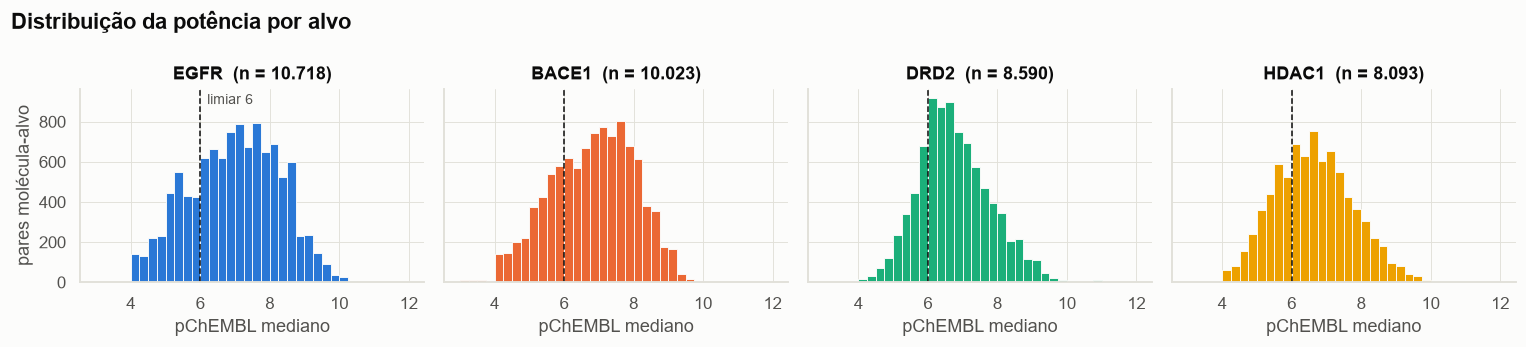

In [14]:
plots.potency_histograms(pairs)

In [15]:
curation.active_share_by_threshold(pairs)

,% com pChEMBL ≥ 5,% com pChEMBL ≥ 6,% com pChEMBL ≥ 7
protein,,,
EGFR,93.3,76.0,51.3
BACE1,92.4,73.3,47.4
DRD2,97.2,77.5,37.5
HDAC1,93.4,69.8,36.7


Com limiar 5, quase tudo vira ativo. Com limiar 7, cada alvo perde metade ou mais das moléculas. Por isso, a molécula é considerada ativa quando o pChEMBL mediano é ≥ 6 (`ACTIVE_THRESHOLD`).

In [16]:
active = curation.select_active(pairs, ACTIVE_THRESHOLD)
print("pares ativos:", len(active))
eda.class_distribution(active, label="protein")

pares ativos: 27798


,linhas,%
protein,,
EGFR,8150,29.3
BACE1,7347,26.4
DRD2,6654,23.9
HDAC1,5647,20.3


### 5.4 Moléculas ativas em mais de um alvo

In [17]:
curation.multi_target_summary(active)

moléculas ativas em mais de um alvo: 42


,moléculas
protein,
EGFR + HDAC1,35
DRD2 + EGFR,4
BACE1 + EGFR,3


Essas moléculas são removidas, porque a classificação multiclasse exige um único rótulo por molécula.

In [18]:
single = curation.remove_multi_target(active)
print("moléculas com rótulo único:", len(single))

moléculas com rótulo único: 27714


## 6. Descritores moleculares

As 5 features vêm do campo `molecule_properties` do ChEMBL (`full_mwt`, `alogp`, `hba`, `hbd`, `psa`), que o próprio ChEMBL calcula sobre a molécula sem sal. É a mesma fonte do CSV do Kaggle, o que a comparação da seção 7 confirma.

In [19]:
properties = download.load_molecule_properties(single["molecule_chembl_id"], refresh=REFRESH)
print("moléculas com propriedades:", len(properties))
print("sha256:", download.file_sha256(PROPERTIES_CSV))

buscadas na API: 0 moléculas
moléculas com propriedades: 27714
sha256: 7d252e2edb53e255be6ec90ab0c164c0c0e46ca0bdaab1f0e80e3d89c18fad8c


## 7. Base final

In [20]:
final = curation.build_final_dataset(single, properties)
print("formato:", final.shape)
print("sha256:", download.file_sha256(FINAL_CSV))
final.head()

formato: (27714, 9)
sha256: 8f951498153e1f5e52ab5ed6575580eb02394fb9865bc2cb53778ab396363c6b


,ChEMBL ID,SMILES,Molecular Weight,LogP,HBA,HBD,TPSA,pChEMBL,Protein
0,CHEMBL100203,Cc1sc(C)c2c1SCc1cnn(C)c1-2,236.37,3.37,4.0,0.0,17.82,6.96,DRD2
1,CHEMBL100454,CN1CCN(C2=Nc3ccccc3Nc3sc(CO)cc32)CC1,328.44,2.62,6.0,2.0,51.10,7.66,DRD2
2,CHEMBL10085,CC(C)Oc1ccccc1N1CCN(Cc2cccc(C(=O)N3CCCCC3)c2)CC1,421.59,4.42,4.0,0.0,36.02,8.66,DRD2
3,CHEMBL101253,Clc1ccc(Nc2nnc(Cc3ccncc3)c3ccccc23)cc1,346.82,5.01,4.0,1.0,50.70,6.34,EGFR
4,CHEMBL101285,Oc1ccccc1OCCNCc1ccccc1,243.31,2.56,3.0,2.0,41.49,6.34,DRD2


In [21]:
curation.compare_with_kaggle(kaggle, final)

moléculas em comum: 525 de 1333
mesmo rótulo: 99.6%


,Molecular Weight,LogP,HBA,HBD,TPSA
% igual ao Kaggle,100.0,99.4,99.4,99.4,99.4


A interseção é parcial porque a base nova só tem moléculas ativas. Nas moléculas em comum, os descritores batem.

## 8. Resumo

1. Download das atividades dos 4 alvos, já filtradas na consulta à API.
2. Remoção de medições suspeitas, duplicadas e sem SMILES.
3. Um valor por par molécula-alvo: a mediana do pChEMBL.
4. Só moléculas ativas (pChEMBL ≥ 6) e com um único alvo.
5. Descritores de `molecule_properties` do ChEMBL.

Saída: `data/processed/chembl_4targets.csv`. Próxima etapa: `02_analise_exploratoria.ipynb`.